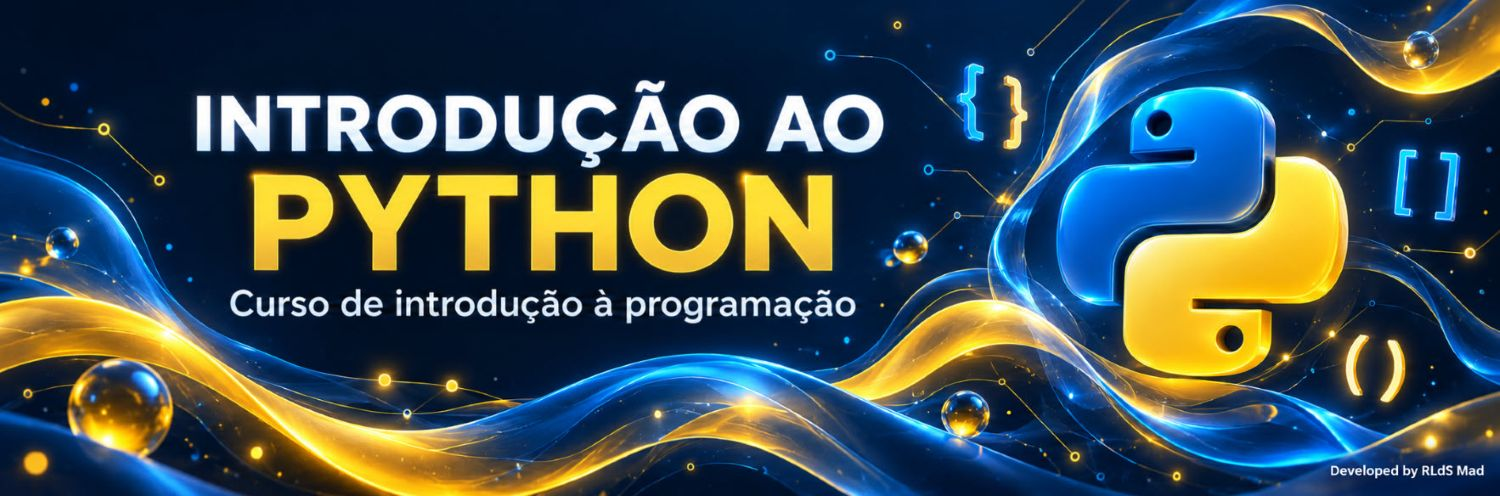

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_08_Otimizacao_Grupos.ipynb)

# Nível IA · Módulo 8 – Otimização combinatória: formar grupos de projeto
## Pesquisa exaustiva, pesquisa local e meta-heurísticas

Muitos problemas de inteligência artificial não pedem uma previsão, mas uma **decisão**: que horário fazer, que rota seguir, como dividir pessoas em equipas. Têm um número finito de soluções possíveis, mas esse número é tão grande que não dá para as experimentar todas. São problemas de **otimização combinatória**, e resolvem-se com **algoritmos de pesquisa**: começam numa solução e vão-na melhorando, passo a passo, com regras que evitam ficar presos.

Neste módulo resolves um caso completo, do enunciado ao relatório de resultados: dividir os alunos de um curso em grupos de projeto, de modo que nenhum grupo fique com um mau ambiente. Começas pela formulação e pela contagem das soluções, resolves os casos pequenos com pesquisa exaustiva e constróis depois, de raiz, três algoritmos clássicos: a **subida de colina**, o **recozimento simulado** e a **pesquisa tabu**. No fim, comparas os três de forma justa e apresentas os resultados como num relatório.

> **Objetivos:** formular um problema de otimização combinatória (solução, restrições e função objetivo); perceber o que significa um problema ser NP-difícil; contar o espaço de soluções e reconhecer quando a pesquisa exaustiva deixa de ser possível; usar a poda para acelerar a pesquisa exaustiva; construir uma solução inicial gulosa; definir vizinhanças e avaliar movimentos de forma incremental; implementar a subida de colina com reinícios, o recozimento simulado e a pesquisa tabu; comparar algoritmos com o mesmo orçamento e reportar resultados (algoritmo, configuração, valor, avaliações, iterações e tempo de CPU).

**Pré-requisitos:** funções (capítulo 18), classes (capítulo 20), NumPy (capítulo 22), visualização (capítulo 24) e geradores (capítulo 25). Não é precisa matemática para além de somas, máximos e potências.

| Secção | Tema |
| --- | --- |
| 0. Preparação | bibliotecas e vocabulário |
| 1. O problema | enunciado, dados e um exemplo à mão |
| 2. Formular o problema | representação, função objetivo e complexidade |
| 3. O tamanho do espaço de soluções | quantas divisões existem |
| 4. Pesquisa exaustiva | gerar todas as divisões; poda |
| 5. Uma solução inicial gulosa | começar bem |
| 6. Vizinhança e avaliação incremental | movimentos, planícies e orçamento |
| 7. Subida de colina | ótimos locais e reinícios |
| 8. Recozimento simulado | aceitar pioras de forma controlada |
| 9. Pesquisa tabu | memória de curto prazo |
| 10. Comparação justa | o mesmo orçamento para todos |
| 11. Resultados e relatório | como apresentar o trabalho |
| 12. Experimenta | três exercícios com solução |

## 0. Preparação

### 0.1 Bibliotecas

Os algoritmos são escritos em Python puro, para se ver cada passo. O NumPy gera os dados, o pandas mostra tabelas e o matplotlib desenha os gráficos.

In [1]:
# Executar esta célula

import itertools
import math
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120)
print(f"NumPy {np.__version__} | pandas {pd.__version__}")

NumPy 2.5.4 | pandas 3.0.6


### 0.2 Vocabulário

| Termo | Significado neste módulo |
| --- | --- |
| **Solução** (ou divisão) | uma forma de dividir todos os alunos em grupos que cumpre as regras |
| **Função objetivo** | o número que mede a qualidade de uma solução; aqui queremos minimizá-lo |
| **Espaço de soluções** | o conjunto de todas as soluções possíveis |
| **Movimento** | uma pequena alteração que transforma uma solução noutra (por exemplo, trocar dois alunos de grupo) |
| **Vizinhança** | todas as soluções a que se chega com um movimento |
| **Avaliação** | calcular o valor de uma solução candidata; é a medida de esforço mais usada |
| **Iteração** | um passo do algoritmo: escolher um movimento e aplicá-lo |
| **Ótimo local** | uma solução sem nenhum vizinho melhor, que pode não ser a melhor de todas |
| **Ótimo global** | a melhor solução de todas |
| **Heurística** | uma regra prática que costuma dar boas soluções, sem garantia de ótimo |
| **Meta-heurística** | uma estratégia geral para guiar heurísticas e fugir de ótimos locais (recozimento simulado, pesquisa tabu, algoritmos genéticos…) |

## 1. O problema

### 1.1 Enunciado

Uma escola vai organizar uma semana de projetos em que todos os alunos de um curso trabalham em grupo. A coordenação sabe, por experiência, que alguns pares de alunos trabalham bem juntos e outros não. No início do ano, cada aluno indicou com quem prefere ou evita trabalhar, e a coordenação resumiu essas respostas num **índice de incompatibilidade** para cada par de alunos: varia entre 0 (trabalham juntos sem qualquer problema) e 1 (incompatibilidade forte), em passos de 0,25.

**Regras:**

- Todos os alunos ficam num grupo, e cada aluno fica num só grupo.
- Cada grupo tem entre **3 e 5 alunos**.
- A **incompatibilidade de um grupo** é a soma dos índices de todos os pares de alunos do grupo. Num grupo de 4 alunos, por exemplo, somam-se os 6 pares.
- O **valor de uma divisão** é a incompatibilidade do **pior grupo**. A coordenação quer que nenhum grupo fique com um ambiente difícil, por isso procura a divisão em que o pior grupo é o menos mau possível.

**Cenários:** os alunos de um cenário fazem parte de todos os cenários maiores.

| Cenário | Alunos (N) | Objetivo |
| --- | --- | --- |
| 1 | 6 | encontrar o ótimo à mão ou por pesquisa exaustiva |
| 2 | 12 | pesquisa exaustiva ainda possível; serve de referência |
| 3 | 24 | comparar pesquisa local e meta-heurísticas |
| 4 | 60 | encontrar uma boa solução dentro do orçamento |
| 5 | 120 | idem, com um espaço de soluções muito maior |

**Orçamento:** em cada cenário, a pesquisa pode usar no máximo **30 segundos de CPU** ou **1 milhão de avaliações**, o que acontecer primeiro.

**Para cada cenário deve indicar:** o algoritmo e a sua configuração (parâmetros e semente); os grupos encontrados e o valor da divisão; o número de avaliações, de iterações e o tempo de CPU.

### 1.2 Os dados

Os índices são gerados com uma semente fixa, para que todos obtenham os mesmos valores. A matriz é gerada sempre para 120 alunos e cada cenário usa os primeiros N: é isso que garante que os alunos do cenário 1 estão em todos os outros.

A matriz é **simétrica** (a incompatibilidade de A com B é a mesma de B com A) e tem zeros na diagonal (um aluno não tem incompatibilidade consigo próprio).

In [2]:
# Executar esta célula

def gerar_incompatibilidades(n, semente=2026):
    # Matriz simétrica n x n com índices 0; 0,25; 0,5; 0,75 ou 1 e diagonal 0.
    rng = np.random.default_rng(semente)
    niveis = np.array([0, 0.25, 0.5, 0.75, 1])
    m = rng.choice(niveis, size=(120, 120), p=[0.05, 0.15, 0.30, 0.30, 0.20])
    m = np.triu(m, 1)  # só a parte acima da diagonal...
    return (m + m.T)[:n, :n]  # ...espelhada para baixo: fica simétrica


CENARIOS = {1: 6, 2: 12, 3: 24, 4: 60, 5: 120}

M120 = gerar_incompatibilidades(120)
print("Simétrica:", np.array_equal(M120, M120.T), "| diagonal a zero:", not M120.diagonal().any())
print("Cenário 1 contido no cenário 5:", np.array_equal(gerar_incompatibilidades(6), M120[:6, :6]))
print("Média dos índices:", round(M120[np.triu_indices(120, 1)].mean(), 3))

Simétrica: True | diagonal a zero: True
Cenário 1 contido no cenário 5: True
Média dos índices: 0.617


Para ler a matriz do cenário 1 como no enunciado, mostramos só a metade de baixo, com os alunos numerados a partir de 1. No código, os alunos são numerados a partir de **0** (são índices de listas); só quando mostramos resultados somamos 1.

In [3]:
# Executar esta célula

def tabela_triangular(m):
    n = len(m)
    linhas = [[m[i, j] if j <= i else "" for j in range(n)] for i in range(n)]
    return pd.DataFrame(linhas, index=range(1, n + 1), columns=range(1, n + 1))


tabela_triangular(gerar_incompatibilidades(6))

,1,2,3,4,5,6
1,0.00,,,,,
2,0.75,0.0,,,,
3,0.50,0.5,0.0,,,
4,0.50,0.5,0.5,0.0,,
5,0.50,0.5,0.25,1.0,0.0,
6,0.75,0.25,0.0,0.5,1.0,0.0


### 1.3 Um exemplo à mão

Com 6 alunos, a única forma de cumprir as regras é fazer **dois grupos de 3**. Cada grupo de 3 tem 3 pares. Para a divisão {1, 2, 3} e {4, 5, 6}:

- grupo {1, 2, 3}: pares 1-2, 1-3 e 2-3, ou seja 0,75 + 0,5 + 0,5 = **1,75**;
- grupo {4, 5, 6}: pares 4-5, 4-6 e 5-6, ou seja 1 + 0,5 + 1 = **2,5**.

O valor da divisão é o do pior grupo: **2,5**. A divisão {1, 2, 5} e {3, 4, 6} tem grupos com 1,75 e 1,0, e vale **1,75**: é melhor, porque o seu pior grupo é menos mau.

> **Experimenta antes de continuar:** com a tabela acima, procura à mão uma divisão melhor do que 1,75. Há 10 divisões possíveis; quantas consegues eliminar sem fazer contas completas?

<details>
<summary><b>Ver uma solução possível</b></summary>

A melhor divisão é **{1, 3, 5} e {2, 4, 6}**, com grupos de 1,25 e 1,25: vale **1,25**. Um atalho útil: os pares com índice 1 (4-5 e 5-6) e 0,75 (1-2 e 1-6) devem ficar separados, o que elimina logo várias divisões. A secção 4 confirma, por pesquisa exaustiva, que não há melhor.

</details>

## 2. Formular o problema

Antes de escrever qualquer algoritmo, é preciso dizer com rigor **o que é uma solução**, **que regras tem de cumprir** e **como se mede a sua qualidade**. Esta formulação é a parte mais importante da análise de um problema de otimização.

### 2.1 Representar uma solução

Uma divisão é uma **lista de grupos**, e cada grupo é uma **lista de alunos**. A função `e_valida` confirma as regras: tamanhos entre 3 e 5, e cada aluno exatamente uma vez.

A matriz é convertida para listas de Python (`tolist()`). Para ler um valor de cada vez, como fazem os algoritmos milhões de vezes, as listas são várias vezes mais rápidas do que um *array* NumPy.

In [4]:
# Executar esta célula

def e_valida(grupos, n, minimo=3, maximo=5):
    tamanhos_ok = all(minimo <= len(g) <= maximo for g in grupos)
    todos_uma_vez = sorted(a for g in grupos for a in g) == list(range(n))
    return tamanhos_ok and todos_uma_vez


def mostrar(grupos):
    # Grupos com os alunos numerados a partir de 1, ordenados para facilitar a leitura.
    return sorted(sorted(a + 1 for a in g) for g in grupos)


A6 = gerar_incompatibilidades(6).tolist()
exemplo = [[0, 1, 2], [3, 4, 5]]
print(mostrar(exemplo), e_valida(exemplo, 6))
print(e_valida([[0, 1], [2, 3, 4, 5]], 6), "(um grupo de 2)")
print(e_valida([[0, 1, 2], [2, 3, 4]], 6), "(aluno 3 repetido e aluno 6 em falta)")

[[1, 2, 3], [4, 5, 6]] True
False (um grupo de 2)
False (aluno 3 repetido e aluno 6 em falta)


### 2.2 A função objetivo

A incompatibilidade de um grupo $G$ é a soma dos índices $a_{ij}$ de todos os seus pares:

$$C(G) = \sum_{i<j,\; i,j \in G} a_{ij}$$

O valor de uma divisão $G_1, \dots, G_m$ é o máximo dessas somas, e queremos a divisão que o torna o mais pequeno possível:

$$\min_{G_1,\dots,G_m} \; \max_{k} \; C(G_k)$$

Por isso se diz que o objetivo é **minimax**: minimizar o máximo. As restrições são as regras do enunciado: $3 \le |G_k| \le 5$, os grupos não se sobrepõem e juntos contêm todos os alunos.

In [5]:
# Executar esta célula

def incompatibilidade_grupo(A, grupo):
    return sum(A[i][j] for i, j in itertools.combinations(grupo, 2))


def valor_divisao(A, grupos):
    return max(incompatibilidade_grupo(A, g) for g in grupos)


for divisao in ([[0, 1, 2], [3, 4, 5]], [[0, 1, 4], [2, 3, 5]]):
    custos = [incompatibilidade_grupo(A6, g) for g in divisao]
    print(mostrar(divisao), "-> grupos:", custos, "| valor:", valor_divisao(A6, divisao))

[[1, 2, 3], [4, 5, 6]] -> grupos: [1.75, 2.5] | valor: 2.5
[[1, 2, 5], [3, 4, 6]] -> grupos: [1.75, 1.0] | valor: 1.75


### 2.3 Minimizar o pior grupo não é minimizar a soma

Seria tentador minimizar a **soma** das incompatibilidades de todos os grupos. Mas isso responde a outra pergunta. Imagina duas divisões de 9 alunos em três grupos:

| Divisão | Grupo 1 | Grupo 2 | Grupo 3 | Soma | Pior grupo |
| --- | --- | --- | --- | --- | --- |
| A | 0,5 | 0,5 | 2,0 | **3,0** | 2,0 |
| B | 1,0 | 1,0 | 1,25 | 3,25 | **1,25** |

A soma prefere A, mas em A um dos grupos fica com um ambiente muito difícil. O critério minimax prefere B, que reparte melhor a dificuldade. É o que a coordenação pede: **justiça entre grupos**, não o menor total. O exercício 1 mostra esta diferença nos dados do caso.

O minimax tem um efeito secundário importante, que vai aparecer na secção 6: muitas alterações não mudam o pior grupo, por isso não mudam o valor.

### 2.4 Que tipo de problema é este?

É um problema de **otimização combinatória**: o espaço de soluções é discreto e finito, e o objetivo é escolher a melhor combinação. Em termos de complexidade, é **NP-difícil**. Convém separar três ideias que se confundem muitas vezes:

- **NP** é uma classe de problemas de **decisão** (resposta sim/não) cujas respostas «sim» se verificam depressa (em tempo polinomial), mesmo que encontrá-las seja difícil. Exemplo: «existe uma divisão com valor ≤ 1?». Dada uma divisão, verificar é fácil.
- **NP-completo**: problemas de NP que são tão difíceis como qualquer outro de NP. Se um deles tivesse um algoritmo rápido, todos teriam.
- **NP-difícil**: problemas pelo menos tão difíceis como os NP-completos, que **não precisam de ser de decisão**. É o caso da versão de otimização («qual é a melhor divisão?»).

Uma forma de ver a dificuldade: pensa nos pares de alunos com índice 0 como as ligações de um grafo. Decidir se os alunos podem ser divididos **em grupos de exatamente 3** com valor 0 é o mesmo que decidir se esse grafo se pode partir em triângulos, um problema NP-completo clássico (*partition into triangles*; Garey e Johnson, 1979). A versão com grupos de 3 a 5 é uma generalização, também difícil, embora a demonstração rigorosa seja mais técnica.

**Na prática,** NP-difícil não quer dizer impossível: quer dizer que não se conhece um algoritmo que encontre **sempre** o ótimo em tempo razoável à medida que N cresce (assumindo P ≠ NP). Para N pequeno, a pesquisa exaustiva chega (secção 4). Para N grande, usam-se heurísticas e meta-heurísticas, que dão soluções muito boas sem garantia de ótimo (secções 5 a 9).

## 3. O tamanho do espaço de soluções

### 3.1 Que tamanhos de grupos são possíveis?

Primeiro, as **distribuições de tamanhos**: com 12 alunos, podemos ter 4 grupos de 3, 3 grupos de 4, ou grupos de 3, 4 e 5. Geramos todas as combinações de tamanhos entre 3 e 5 que somam N. A ordem não interessa, por isso usamos `combinations_with_replacement`, que gera cada combinação uma só vez e em ordem crescente.

In [6]:
# Executar esta célula

def distribuicoes(n, minimo=3, maximo=5):
    resultado = []
    for k in range(math.ceil(n / maximo), n // minimo + 1):  # número de grupos possível
        for tamanhos in itertools.combinations_with_replacement(range(minimo, maximo + 1), k):
            if sum(tamanhos) == n:
                resultado.append(tamanhos)
    return resultado


for n in (6, 9, 12):
    print(n, "alunos:", distribuicoes(n))

6 alunos: [(3, 3)]
9 alunos: [(4, 5), (3, 3, 3)]
12 alunos: [(3, 4, 5), (4, 4, 4), (3, 3, 3, 3)]


### 3.2 Contar as divisões

Para uma distribuição de tamanhos $s_1, \dots, s_m$, o número de divisões obtém-se a partir das $N!$ ordenações dos alunos: cortamos a fila nos tamanhos pedidos e corrigimos o que foi contado a mais.

$$\frac{N!}{\prod_k s_k! \; \prod_s r_s!}$$

- Dividimos por $s_k!$ porque a ordem **dentro** de cada grupo não interessa: {1, 2, 3} é o mesmo grupo que {3, 1, 2}.
- Dividimos por $r_s!$, em que $r_s$ é o número de grupos com o tamanho $s$, porque a ordem **entre grupos do mesmo tamanho** também não interessa: «{1, 2, 3} e {4, 5, 6}» é a mesma divisão que «{4, 5, 6} e {1, 2, 3}».

Somando todas as distribuições, temos o total.

In [7]:
# Executar esta célula

def contar_divisoes(n):
    total = 0
    for tamanhos in distribuicoes(n):
        denominador = 1
        for s in tamanhos:
            denominador *= math.factorial(s)
        for repeticoes in Counter(tamanhos).values():
            denominador *= math.factorial(repeticoes)
        total += math.factorial(n) // denominador
    return total


linhas = []
for cenario, n in CENARIOS.items():
    total = contar_divisoes(n)
    anos = total / 1e6 / (3600 * 24 * 365)  # a 1 milhão de divisões por segundo
    linhas.append({"cenário": cenario, "N": n, "divisões": f"{total:.3e}" if total > 1e6 else total,
                   "tempo a 1 milhão/s": f"{total / 1e6:.2g} s" if anos < 1e-3 else f"{anos:.2g} anos"})
pd.DataFrame(linhas).set_index("cenário")

,N,divisões,tempo a 1 milhão/s
cenário,,,
1,6,10,1e-05 s
2,12,48895,0.049 s
3,24,9.044e+14,29 anos
4,60,2.225e+55,7.1e+41 anos
5,120,6.308e+137,2e+124 anos


Com 6 alunos há 10 divisões e com 12 há menos de 50 mil: a pesquisa exaustiva é instantânea. Com 24 alunos já são perto de $10^{15}$, o que levaria anos mesmo a um milhão de divisões por segundo. Com 120 alunos, o número tem 138 algarismos. O gráfico, em escala logarítmica, mostra este crescimento **mais do que exponencial**:

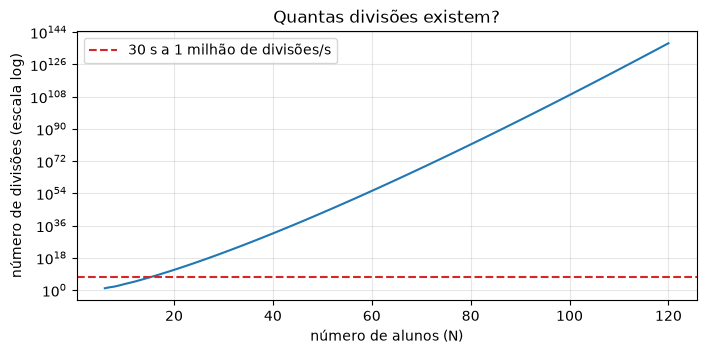

In [8]:
# Executar esta célula

ns = list(range(6, 121))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.semilogy(ns, [contar_divisoes(n) for n in ns])
ax.axhline(1e6 * 30, color="tab:red", linestyle="--", label="30 s a 1 milhão de divisões/s")
ax.set_xlabel("número de alunos (N)")
ax.set_ylabel("número de divisões (escala log)")
ax.set_title("Quantas divisões existem?")
ax.legend()
plt.show()

## 4. Pesquisa exaustiva

### 4.1 Gerar cada divisão uma só vez

Gerar todas as divisões sem repetições exige um truque: o **primeiro aluno ainda sem grupo** abre sempre o grupo seguinte. Assim, «{1, 2, 3} e {4, 5, 6}» só é gerada uma vez, porque o aluno 1 está sempre no primeiro grupo. A função é **recursiva** (capítulo 18) e é um **gerador** (capítulo 25): devolve as divisões uma a uma com `yield`, sem as guardar todas em memória.

In [9]:
# Executar esta célula

def gerar_divisoes(alunos, tamanhos):
    # Gera todas as divisões de `alunos` com os tamanhos indicados, sem repetições.
    if not alunos:
        yield []
        return
    primeiro, outros = alunos[0], alunos[1:]
    for t in sorted(set(tamanhos)):  # tamanho do grupo que o primeiro aluno abre
        tamanhos_restantes = list(tamanhos)
        tamanhos_restantes.remove(t)
        for colegas in itertools.combinations(outros, t - 1):
            restantes = [a for a in outros if a not in colegas]
            for resto in gerar_divisoes(restantes, tamanhos_restantes):
                yield [[primeiro, *colegas], *resto]


# Confirmar que gera exatamente o número calculado na secção 3
for n in (6, 9, 12):
    geradas = sum(1 for d in distribuicoes(n) for _ in gerar_divisoes(list(range(n)), list(d)))
    print(f"N = {n:2d}: geradas {geradas:6d} | calculadas {contar_divisoes(n):6d}")

N =  6: geradas     10 | calculadas     10
N =  9: geradas    406 | calculadas    406
N = 12: geradas  48895 | calculadas  48895


### 4.2 Resolver os cenários 1 e 2

A pesquisa exaustiva percorre todas as divisões, avalia cada uma e guarda a melhor. Garante o ótimo, porque não deixa nenhuma de fora. Para o cenário 1 mostramos as 10 divisões, ordenadas pelo valor:

In [10]:
# Executar esta célula

def pesquisa_exaustiva(A, n):
    melhor, melhor_valor, avaliacoes = None, math.inf, 0
    for tamanhos in distribuicoes(n):
        for divisao in gerar_divisoes(list(range(n)), list(tamanhos)):
            avaliacoes += 1
            v = valor_divisao(A, divisao)
            if v < melhor_valor:
                melhor, melhor_valor = divisao, v
    return melhor, melhor_valor, avaliacoes


linhas = []
for divisao in gerar_divisoes(list(range(6)), [3, 3]):
    custos = [incompatibilidade_grupo(A6, g) for g in divisao]
    linhas.append({"divisão": mostrar(divisao), "grupos": custos, "soma": sum(custos), "valor (pior grupo)": max(custos)})
pd.DataFrame(linhas).sort_values("valor (pior grupo)").reset_index(drop=True)

,divisão,grupos,soma,valor (pior grupo)
0,"[[1, 3, 5], [2, 4, 6]]","[1.25, 1.25]",2.50,1.25
1,"[[1, 2, 4], [3, 5, 6]]","[1.75, 1.25]",3.00,1.75
2,"[[1, 2, 6], [3, 4, 5]]","[1.75, 1.75]",3.50,1.75
3,"[[1, 2, 5], [3, 4, 6]]","[1.75, 1.0]",2.75,1.75
4,"[[1, 3, 4], [2, 5, 6]]","[1.5, 1.75]",3.25,1.75
5,"[[1, 4, 6], [2, 3, 5]]","[1.75, 1.25]",3.00,1.75
6,"[[1, 4, 5], [2, 3, 6]]","[2.0, 0.75]",2.75,2.00
7,"[[1, 3, 6], [2, 4, 5]]","[1.25, 2.0]",3.25,2.00
8,"[[1, 5, 6], [2, 3, 4]]","[2.25, 1.5]",3.75,2.25
9,"[[1, 2, 3], [4, 5, 6]]","[1.75, 2.5]",4.25,2.50


In [11]:
# Executar esta célula

for cenario in (1, 2):
    n = CENARIOS[cenario]
    A = gerar_incompatibilidades(n).tolist()
    inicio = time.process_time()
    melhor, v, avaliacoes = pesquisa_exaustiva(A, n)
    cpu = time.process_time() - inicio
    print(f"Cenário {cenario} (N = {n}): ótimo = {v} | {avaliacoes} avaliações | {cpu:.2f} s de CPU")
    print("   ", mostrar(melhor))

Cenário 1 (N = 6): ótimo = 1.25 | 10 avaliações | 0.00 s de CPU
    [[1, 3, 5], [2, 4, 6]]


Cenário 2 (N = 12): ótimo = 1.5 | 48895 avaliações | 0.18 s de CPU
    [[1, 3, 4], [2, 6, 9], [5, 7, 11], [8, 10, 12]]


Estes dois ótimos são a nossa **referência**: qualquer algoritmo heurístico deve encontrá-los nos cenários 1 e 2. É uma forma simples de testar o código antes de o usar onde não se conhece o ótimo.

### 4.3 Poda: não completar divisões que já perderam

Muitas divisões nem precisam de ser completadas. Se já temos uma divisão com valor 1,5 e um grupo em construção já tem incompatibilidade 1,5 ou mais, nenhuma divisão que contenha esse grupo pode ser melhor: o valor é o pior grupo, e esse grupo já não é melhor do que 1,5. Podemos **podar** esse ramo inteiro da pesquisa.

É a ideia do ***branch and bound*** (ramificar e limitar): a pesquisa ramifica-se grupo a grupo, e o melhor valor conhecido serve de limite para cortar ramos. Continua a garantir o ótimo, porque só se cortam ramos que não o podem conter.

In [12]:
# Executar esta célula

def pesquisa_com_poda(A, n):
    melhor = {"valor": math.inf, "divisao": None}
    contagem = {"grupos avaliados": 0, "divisões completas": 0}

    def ramificar(alunos, tamanhos, grupos, pior_ate_agora):
        if not alunos:
            contagem["divisões completas"] += 1
            melhor["valor"], melhor["divisao"] = pior_ate_agora, grupos
            return
        primeiro, outros = alunos[0], alunos[1:]
        for t in sorted(set(tamanhos)):
            tamanhos_restantes = list(tamanhos)
            tamanhos_restantes.remove(t)
            for colegas in itertools.combinations(outros, t - 1):
                grupo = [primeiro, *colegas]
                contagem["grupos avaliados"] += 1
                pior = max(pior_ate_agora, incompatibilidade_grupo(A, grupo))
                if pior >= melhor["valor"]:  # poda: este ramo não pode melhorar
                    continue
                restantes = [a for a in outros if a not in colegas]
                ramificar(restantes, tamanhos_restantes, grupos + [grupo], pior)

    for tamanhos in distribuicoes(n):
        ramificar(list(range(n)), list(tamanhos), [], 0.0)
    return melhor["divisao"], melhor["valor"], contagem


A12 = gerar_incompatibilidades(12).tolist()
for nome, funcao in (("sem poda", pesquisa_exaustiva), ("com poda", pesquisa_com_poda)):
    inicio = time.process_time()
    divisao, v, esforco = funcao(A12, 12)
    print(f"{nome}: valor {v} | esforço: {esforco} | {time.process_time() - inicio:.3f} s")

sem poda: valor 1.5 | esforço: 48895 | 0.162 s
com poda: valor 1.5 | esforço: {'grupos avaliados': 15340, 'divisões completas': 16} | 0.014 s


Sem poda, avaliam-se as 48 895 divisões, cada uma com 3 ou 4 grupos: mais de 160 mil grupos. Com a poda, chega-se ao mesmo ótimo completando apenas algumas divisões e avaliando menos de um décimo dos grupos, em cerca de um décimo do tempo. Mas a poda não muda a natureza do problema: com 24 alunos, mesmo cortando 99,9 % dos ramos, ficariam ainda biliões de divisões. Para os cenários 3 a 5 é preciso outra abordagem.

## 5. Uma solução inicial gulosa

Os algoritmos das próximas secções partem de uma solução e melhoram-na. Podemos começar ao acaso, mas uma boa solução inicial poupa trabalho. Precisamos de duas decisões.

**Quantos grupos?** Um grupo de 3 tem 3 pares, um de 4 tem 6 e um de 5 tem 10. Com 12 alunos, 4 grupos de 3 somam 12 pares e 3 grupos de 4 somam 18. Menos pares significa menos incompatibilidade a repartir, por isso começamos com **o maior número de grupos possível**. Os algoritmos podem depois mudar os tamanhos, com transferências (secção 6).

**Quem vai para onde?** Uma **heurística gulosa** toma, em cada passo, a decisão que parece melhor no momento, sem voltar atrás. Colocamos primeiro os alunos mais «difíceis» (maior soma de incompatibilidades com todos os outros), cada um no grupo com lugar onde aumenta menos a incompatibilidade.

In [13]:
# Executar esta célula

def tamanhos_iniciais(n):
    maximo_grupos = max(len(d) for d in distribuicoes(n))
    return sorted(next(d for d in distribuicoes(n) if len(d) == maximo_grupos))


def divisao_aleatoria(n, rng):
    alunos = rng.permutation(n).tolist()
    grupos, inicio = [], 0
    for t in tamanhos_iniciais(n):
        grupos.append(alunos[inicio:inicio + t])
        inicio += t
    return grupos


def divisao_gulosa(A, n):
    tamanhos = tamanhos_iniciais(n)
    grupos = [[] for _ in tamanhos]
    custos = [0.0] * len(tamanhos)
    por_dificuldade = sorted(range(n), key=lambda a: sum(A[a]), reverse=True)
    for aluno in por_dificuldade:
        # Entre os grupos com lugar, o que fica com menor incompatibilidade (desempate: o mais vazio).
        melhor = min((custos[g] + sum(A[aluno][b] for b in grupos[g]), len(grupos[g]), g)
                     for g in range(len(grupos)) if len(grupos[g]) < tamanhos[g])
        novo_custo, _, g = melhor
        grupos[g].append(aluno)
        custos[g] = novo_custo
    return grupos


print("Tamanhos iniciais para 12 alunos:", tamanhos_iniciais(12), "| para 60:", tamanhos_iniciais(60)[:3], "...")
rng = np.random.default_rng(0)
linhas = []
for cenario in (3, 4, 5):
    n = CENARIOS[cenario]
    A = gerar_incompatibilidades(n).tolist()
    aleatorias = [valor_divisao(A, divisao_aleatoria(n, rng)) for _ in range(200)]
    gulosa = divisao_gulosa(A, n)
    assert e_valida(gulosa, n)
    linhas.append({"cenário": cenario, "N": n, "aleatória (média de 200)": round(np.mean(aleatorias), 2),
                   "melhor de 200 aleatórias": min(aleatorias), "gulosa": valor_divisao(A, gulosa)})
pd.DataFrame(linhas).set_index("cenário")

Tamanhos iniciais para 12 alunos: [3, 3, 3, 3] | para 60: [3, 3, 3] ...


,N,aleatória (média de 200),melhor de 200 aleatórias,gulosa
cenário,,,,
3,24,2.51,1.75,2.0
4,60,2.68,2.00,1.5
5,120,2.77,2.50,1.5


A gulosa é muito melhor do que uma divisão ao acaso típica e, nos cenários 4 e 5, até do que a melhor de 200 divisões aleatórias, quase sem custo. No cenário 3, porém, uma das 200 aleatórias foi melhor: uma heurística gulosa não dá garantias. E está longe do que os algoritmos seguintes vão conseguir. É um bom ponto de partida, não um ponto de chegada.

## 6. Vizinhança e avaliação incremental

### 6.1 Os movimentos

A pesquisa local anda de solução em solução através de **movimentos** pequenos. Usamos dois, e ambos mantêm a solução válida:

- **Troca:** o aluno `x` do grupo `i` troca com o aluno `y` do grupo `j`. Os tamanhos não mudam.
- **Transferência:** o aluno `x` passa do grupo `i` para o grupo `j`. Só é permitida se `i` ficar com pelo menos 3 alunos e `j` com no máximo 5. É o movimento que permite mudar a distribuição de tamanhos.

Um movimento é representado por um tuplo `(tipo, i, x, j, y)`; numa transferência, `y` é `None`.

### 6.2 Avaliação incremental

Avaliar uma solução do zero obriga a somar todos os pares de todos os grupos. Mas um movimento só altera **dois grupos**, e nesses dois só mudam os pares que envolvem os alunos que se mexeram. Se guardarmos o custo de cada grupo, basta corrigir:

- quando `x` sai do grupo $G$, o custo de $G$ perde as ligações de `x` aos colegas: $C(G) - \sum_{g \in G} a_{xg}$;
- quando `y` entra, ganha as ligações de `y` aos novos colegas: $+ \sum_{g \in G \setminus \{x\}} a_{yg}$.

A classe `Estado` guarda os grupos e os seus custos; `custos_apos` calcula os custos depois de um movimento **sem o aplicar**, e `aplicar` faz a alteração.

In [14]:
# Executar esta célula

def ligacao(A, aluno, grupo, sem=None):
    # Soma dos índices entre `aluno` e os elementos de `grupo` (exceto ele próprio e `sem`).
    linha = A[aluno]
    return sum(linha[g] for g in grupo if g != aluno and g != sem)


class Estado:
    def __init__(self, A, grupos):
        self.A = A
        self.grupos = [list(g) for g in grupos]
        self.custos = [incompatibilidade_grupo(A, g) for g in self.grupos]

    def copia(self):
        novo = Estado.__new__(Estado)
        novo.A, novo.grupos, novo.custos = self.A, [g[:] for g in self.grupos], self.custos[:]
        return novo

    def valor(self):
        return max(self.custos)

    def custos_apos(self, movimento):
        tipo, i, x, j, y = movimento
        gi, gj = self.grupos[i], self.grupos[j]
        custos = self.custos[:]
        if tipo == "troca":
            custos[i] = self.custos[i] - ligacao(self.A, x, gi) + ligacao(self.A, y, gi, sem=x)
            custos[j] = self.custos[j] - ligacao(self.A, y, gj) + ligacao(self.A, x, gj, sem=y)
        else:  # transferência
            custos[i] = self.custos[i] - ligacao(self.A, x, gi)
            custos[j] = self.custos[j] + ligacao(self.A, x, gj)
        return custos

    def aplicar(self, movimento, custos):
        tipo, i, x, j, y = movimento
        if tipo == "troca":
            gi, gj = self.grupos[i], self.grupos[j]
            gi[gi.index(x)], gj[gj.index(y)] = y, x
        else:
            self.grupos[i].remove(x)
            self.grupos[j].append(x)
        self.custos = custos

Uma otimização destas tem de ser **verificada**: fazemos 2000 movimentos ao acaso e confirmamos que os custos incrementais coincidem sempre com um cálculo do zero. Depois medimos o ganho de tempo.

In [15]:
# Executar esta célula

def movimento_aleatorio(estado, rng):
    k = len(estado.grupos)
    i, j = (int(v) for v in rng.choice(k, 2, replace=False))
    gi, gj = estado.grupos[i], estado.grupos[j]
    x = gi[rng.integers(len(gi))]
    if rng.random() < 0.3 and len(gi) > 3 and len(gj) < 5:
        return ("transferência", i, x, j, None)
    return ("troca", i, x, j, gj[rng.integers(len(gj))])


A60 = gerar_incompatibilidades(60).tolist()
rng = np.random.default_rng(1)
estado = Estado(A60, divisao_gulosa(A60, 60))
diferenca_maxima, tempo_incremental, tempo_completo = 0.0, 0.0, 0.0
for _ in range(2000):
    mov = movimento_aleatorio(estado, rng)
    t0 = time.perf_counter()
    custos = estado.custos_apos(mov)
    t1 = time.perf_counter()
    estado.aplicar(mov, custos)
    t2 = time.perf_counter()
    do_zero = [incompatibilidade_grupo(A60, g) for g in estado.grupos]
    t3 = time.perf_counter()
    tempo_incremental += t1 - t0
    tempo_completo += t3 - t2
    diferenca_maxima = max(diferenca_maxima, max(abs(a - b) for a, b in zip(custos, do_zero)))

print("Divisão continua válida:", e_valida(estado.grupos, 60))
print("Maior diferença entre incremental e do zero:", diferenca_maxima)
print(f"Tempo por avaliação: incremental {tempo_incremental / 2000 * 1e6:.1f} µs | do zero {tempo_completo / 2000 * 1e6:.1f} µs")

Divisão continua válida: True
Maior diferença entre incremental e do zero: 0.0
Tempo por avaliação: incremental 5.3 µs | do zero 14.5 µs


Com 60 alunos, a avaliação incremental é cerca de três vezes mais rápida, e a diferença cresce com N: o cálculo do zero percorre todos os grupos, o incremental só dois. Num algoritmo que faz um milhão de avaliações, é a diferença entre segundos e minutos.

### 6.3 O problema das planícies

O valor de uma divisão só depende do **pior** grupo. Por isso, muitos movimentos não o alteram: mexem em grupos que não são o pior. Contamos, para a solução gulosa do cenário 4, quantas trocas melhoram, mantêm e pioram o valor:

In [16]:
# Executar esta célula

estado = Estado(A60, divisao_gulosa(A60, 60))
atual = estado.valor()
contagem = Counter()
for i in range(len(estado.grupos)):
    for j in range(i + 1, len(estado.grupos)):
        for x in estado.grupos[i]:
            for y in estado.grupos[j]:
                novo = max(estado.custos_apos(("troca", i, x, j, y)))
                contagem["melhora" if novo < atual else "mantém" if novo == atual else "piora"] += 1
total = sum(contagem.values())
for categoria in ("melhora", "mantém", "piora"):
    print(f"{categoria:8s}: {contagem[categoria]:5d} ({contagem[categoria] / total:.0%})")

melhora :     0 (0%)
mantém  :   484 (28%)
piora   :  1226 (72%)


Nenhuma troca melhora o valor. A solução gulosa tem três grupos empatados no custo máximo (1,5), e uma troca só mexe em dois grupos: mesmo que alivie dois deles, o terceiro continua a 1,5. Mas cerca de um quarto das trocas **mantém** o valor, e entre elas estão as que aliviam um dos piores grupos, o primeiro passo para melhorar depois. Olhando só para o pior grupo, a pesquisa não as distingue das trocas inúteis. O terreno é uma **planície**: muitos vizinhos parecem iguais e não há direção para onde descer.

Para dar uma direção, usamos um **critério de desempate**. Comparamos as soluções pelo tuplo `(pior grupo, soma dos quadrados dos custos)`. Com o mesmo pior grupo, preferimos a solução cujos grupos estão, no conjunto, menos carregados. Os quadrados pesam mais os grupos mais altos, que são os candidatos a pior grupo no futuro. O Python compara tuplos elemento a elemento, por isso `<` faz exatamente o que queremos.

In [17]:
# Executar esta célula

def objetivo(custos):
    return (max(custos), sum(c * c for c in custos))


print(objetivo([1.0, 0.5, 0.5]) < objetivo([1.0, 1.0, 0.25]))  # mesmo pior grupo; o primeiro tem a soma dos quadrados menor

True


### 6.4 A vizinhança focada

Se o valor é o pior grupo, **só um movimento que mexa num grupo com o custo máximo o pode baixar**. Uma troca entre dois grupos «bons» nunca melhora o valor, e pode até criar um novo pior grupo. Por isso definimos duas vizinhanças:

- **completa:** todas as trocas e transferências entre todos os pares de grupos;
- **focada:** só os movimentos que tiram alguém de um grupo com o custo máximo.

A vizinhança focada é muito mais pequena, o que deixa fazer muito mais iterações com o mesmo número de avaliações.

In [18]:
# Executar esta célula

def vizinhanca(estado, focada=True):
    k = len(estado.grupos)
    pior = max(estado.custos)
    origens = [i for i in range(k) if estado.custos[i] >= pior - 1e-12] if focada else list(range(k))
    for i in origens:
        gi = estado.grupos[i]
        for j in range(k):
            if j == i:
                continue
            gj = estado.grupos[j]
            if not (j in origens and j < i):  # não repetir a troca i<->j
                for x in gi:
                    for y in gj:
                        yield ("troca", i, x, j, y)
            if len(gi) > 3 and len(gj) < 5:
                for x in gi:
                    yield ("transferência", i, x, j, None)


for n in (24, 60, 120):
    A = gerar_incompatibilidades(n).tolist()
    e = Estado(A, divisao_gulosa(A, n))
    print(f"N = {n:3d}: vizinhança completa {sum(1 for _ in vizinhanca(e, False)):5d} | focada {sum(1 for _ in vizinhanca(e, True)):4d}")

N =  24: vizinhança completa   252 | focada   63
N =  60: vizinhança completa  1710 | focada  486
N = 120: vizinhança completa  7020 | focada  351


### 6.5 Contar o esforço e respeitar o orçamento

O enunciado pede o número de avaliações e o tempo de CPU, e limita ambos. A classe `Orcamento` conta as avaliações e mede o tempo de CPU com `time.process_time()`, que só conta o tempo em que o processo está a trabalhar (ao contrário do relógio de parede, não é afetado por outros programas). Todos os algoritmos recebem o mesmo tipo de orçamento e param quando ele se esgota. É a mesma ideia de um **orçamento global de CPU** partilhado por todas as fases da pesquisa.

Verificar o relógio também custa tempo, por isso só o fazemos de 1000 em 1000 avaliações.

In [19]:
# Executar esta célula

class Orcamento:
    def __init__(self, max_avaliacoes=1_000_000, max_cpu=30.0):
        self.max_avaliacoes = max_avaliacoes
        self.max_cpu = max_cpu
        self.avaliacoes = 0
        self.inicio = time.process_time()

    def gastar(self, n=1):
        self.avaliacoes += n

    def esgotado(self):
        if self.avaliacoes >= self.max_avaliacoes:
            return True
        return self.avaliacoes % 1000 == 0 and self.cpu() >= self.max_cpu

    def cpu(self):
        return time.process_time() - self.inicio

## 7. Subida de colina

### 7.1 O algoritmo

A **subida de colina** (*hill climbing*; aqui, como minimizamos, seria mais correto dizer «descida») é o algoritmo de pesquisa local mais simples:

```text
solução ← solução inicial
repetir:
    avaliar todos os vizinhos da solução
    se nenhum é melhor: parar (ótimo local)
    solução ← o melhor vizinho
```

Esta variante, que avalia todos os vizinhos e escolhe o melhor, chama-se **subida pelo maior declive** (*steepest ascent*). Guardamos também o **histórico**: a cada iteração, o número de avaliações gastas e o valor atual, para desenhar a evolução.

In [20]:
# Executar esta célula

def subida_colina(A, grupos, orcamento, focada=True):
    estado = Estado(A, grupos)
    atual = objetivo(estado.custos)
    historico = [(orcamento.avaliacoes, atual[0])]
    iteracoes = 0
    while not orcamento.esgotado():
        melhor = None
        for mov in vizinhanca(estado, focada):
            if orcamento.esgotado():
                break
            custos = estado.custos_apos(mov)
            orcamento.gastar()
            ob = objetivo(custos)
            if ob < atual and (melhor is None or ob < melhor[0]):
                melhor = (ob, mov, custos)
        if melhor is None:  # nenhum vizinho melhor: ótimo local
            break
        atual, mov, custos = melhor
        estado.aplicar(mov, custos)
        iteracoes += 1
        historico.append((orcamento.avaliacoes, atual[0]))
    return estado, {"iterações": iteracoes}, historico


A24 = gerar_incompatibilidades(24).tolist()
orc = Orcamento(max_avaliacoes=1_000_000)
estado, info, historico = subida_colina(A24, divisao_gulosa(A24, 24), orc)
print(f"Valor: {valor_divisao(A24, divisao_gulosa(A24, 24))} (gulosa) -> {estado.valor()} | "
      f"{info['iterações']} iterações | {orc.avaliacoes} avaliações | {orc.cpu():.2f} s")

Valor: 2.0 (gulosa) -> 1.25 | 3 iterações | 306 avaliações | 0.00 s


A subida parou muito antes de esgotar o orçamento: chegou a um **ótimo local**, uma divisão em que nenhum movimento a melhora. Não sabemos se é o ótimo global. Neste problema, com tantas planícies e vales, é quase certo que não.

### 7.2 Reinícios aleatórios

A forma mais simples de escapar é **recomeçar** de outro ponto: quando a subida para, começa de novo a partir de uma divisão aleatória, e no fim fica-se com a melhor de todas. Chama-se **subida de colina com reinícios aleatórios** (*random-restart hill climbing*). A primeira subida parte da solução que receber; as seguintes partem de divisões aleatórias.

In [21]:
# Executar esta célula

def subida_com_reinicios(A, n, grupos, orcamento, rng, focada=True):
    melhor, iteracoes, reinicios = None, 0, 0
    historico = []
    inicio = grupos
    while not orcamento.esgotado():
        estado, info, hist = subida_colina(A, inicio, orcamento, focada)
        iteracoes += info["iterações"]
        reinicios += 1
        # Histórico do melhor valor até agora, ao longo de todas as subidas
        for avaliacoes, v in hist:
            historico.append((avaliacoes, v if melhor is None else min(v, melhor.valor())))
        if melhor is None or objetivo(estado.custos) < objetivo(melhor.custos):
            melhor = estado.copia()
        inicio = divisao_aleatoria(n, rng)
    return melhor, {"iterações": iteracoes, "reinícios": reinicios}, historico


for focada in (True, False):
    orc = Orcamento(max_avaliacoes=200_000)
    estado, info, _ = subida_com_reinicios(A60, 60, divisao_gulosa(A60, 60), orc, np.random.default_rng(0), focada)
    print(f"N = 60, vizinhança {'focada ' if focada else 'completa'}: valor {estado.valor()} | "
          f"{info['reinícios']} subidas | {info['iterações']} iterações | {orc.cpu():.2f} s")

N = 60, vizinhança focada : valor 1.0 | 15 subidas | 342 iterações | 0.67 s


N = 60, vizinhança completa: valor 1.0 | 5 subidas | 113 iterações | 0.66 s


Com o mesmo orçamento de 200 mil avaliações, a vizinhança focada faz várias vezes mais subidas, porque cada iteração custa menos avaliações. Tem também mais hipóteses de encontrar uma boa divisão. É um exemplo de uma regra geral: **conhecer a estrutura do problema** (aqui, que só o pior grupo conta) vale mais do que afinar parâmetros.

## 8. Recozimento simulado

### 8.1 Aceitar pioras, de forma controlada

O **recozimento simulado** (*simulated annealing*) inspira-se no arrefecimento lento de um metal, que deixa os átomos organizarem-se numa estrutura estável. Em vez de avaliar a vizinhança toda, escolhe **um vizinho ao acaso** e decide se o aceita:

- se é melhor ou igual, aceita sempre;
- se é pior por uma diferença $\Delta > 0$, aceita com probabilidade $e^{-\Delta / T}$.

$T$ é a **temperatura**. Com $T$ alta, aceita quase tudo e explora livremente; com $T$ baixa, quase só aceita melhorias e comporta-se como a subida de colina. A temperatura começa alta e vai baixando: no início explora, no fim refina.

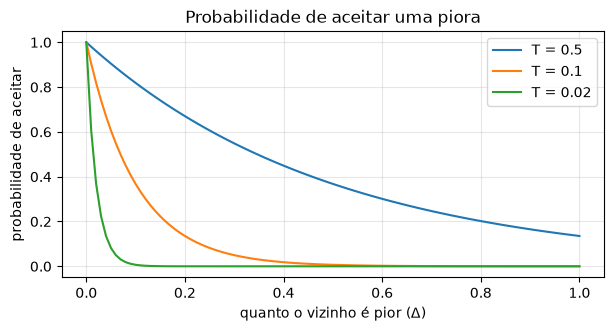

In [22]:
# Executar esta célula

deltas = np.linspace(0, 1, 101)
fig, ax = plt.subplots(figsize=(7, 3.2))
for T in (0.5, 0.1, 0.02):
    ax.plot(deltas, np.exp(-deltas / T), label=f"T = {T}")
ax.set_xlabel("quanto o vizinho é pior (Δ)")
ax.set_ylabel("probabilidade de aceitar")
ax.set_title("Probabilidade de aceitar uma piora")
ax.legend()
plt.show()

### 8.2 A energia: o máximo não serve

O recozimento precisa de um único número para calcular $\Delta$, a que se chama **energia**. Usar diretamente o pior grupo tem o problema das planícies (secção 6.3): quase todos os movimentos têm $\Delta = 0$, são aceites, e a pesquisa vagueia sem direção. Também não podemos usar o tuplo da secção 6.3, porque não se subtraem tuplos.

A solução é um **máximo suave**: a média das potências de grau 4 dos custos, elevada a 1/4.

$$E = \left( \frac{1}{m} \sum_k C(G_k)^4 \right)^{1/4}$$

Com potências altas, os grupos mais carregados dominam a soma, por isso $E$ comporta-se quase como o máximo. Mas $E$ também baixa quando um grupo que **não** é o pior fica melhor, e isso dá à pesquisa uma direção mesmo nas planícies.

In [23]:
# Executar esta célula

def energia_maximo(custos):
    return max(custos)


def energia_suave(custos):
    return (sum(c ** 4 for c in custos) / len(custos)) ** 0.25


def recozimento_simulado(A, grupos, orcamento, rng, t_inicial=0.05, t_final=0.001, energia=energia_suave):
    estado = Estado(A, grupos)
    e_atual = energia(estado.custos)
    melhor, ob_melhor = estado.copia(), objetivo(estado.custos)
    # Arrefecimento geométrico: T é multiplicada por alfa em cada passo,
    # de forma a ir de t_inicial a t_final no orçamento de avaliações.
    alfa = (t_final / t_inicial) ** (1 / orcamento.max_avaliacoes)
    T = t_inicial
    historico = [(orcamento.avaliacoes, ob_melhor[0])]
    passos = aceites = 0
    while not orcamento.esgotado():
        mov = movimento_aleatorio(estado, rng)
        custos = estado.custos_apos(mov)
        orcamento.gastar()
        passos += 1
        delta = energia(custos) - e_atual
        if delta <= 0 or rng.random() < math.exp(-delta / T):
            estado.aplicar(mov, custos)
            e_atual += delta
            aceites += 1
            ob = objetivo(custos)
            if ob < ob_melhor:  # guardar a melhor solução vista, não só a atual
                melhor, ob_melhor = estado.copia(), ob
                historico.append((orcamento.avaliacoes, ob[0]))
        T *= alfa
    historico.append((orcamento.avaliacoes, ob_melhor[0]))
    return melhor, {"iterações": passos, "aceites": aceites, "T final": round(T, 5)}, historico

Três pormenores importantes:

- A **temperatura inicial** deve estar na escala dos $\Delta$ típicos. Os custos mudam em passos de 0,25, e a energia suave muda menos; com $T_0 = 0{,}05$, uma piora pequena ainda é aceite muitas vezes no início.
- O **arrefecimento geométrico** multiplica $T$ por um fator $\alpha$ ligeiramente abaixo de 1 em cada passo. Calculamos $\alpha$ a partir do orçamento, para que $T$ chegue ao valor final exatamente quando as avaliações acabam.
- O recozimento pode **piorar**, por isso guardamos à parte a **melhor solução vista**, e é essa que se devolve.

Vamos comparar as duas energias no cenário 5, com o mesmo orçamento e a mesma solução inicial:

In [24]:
# Executar esta célula

A120 = gerar_incompatibilidades(120).tolist()
inicial = divisao_aleatoria(120, np.random.default_rng(0))
for nome, energia in (("pior grupo", energia_maximo), ("máximo suave", energia_suave)):
    orc = Orcamento(max_avaliacoes=200_000)
    estado, info, _ = recozimento_simulado(A120, inicial, orc, np.random.default_rng(0), energia=energia)
    print(f"Energia = {nome:12s}: valor {estado.valor()} | movimentos aceites {info['aceites']:6d} de {info['iterações']} | {orc.cpu():.1f} s")

Energia = pior grupo  : valor 2.0 | movimentos aceites 122621 de 200000 | 3.1 s


Energia = máximo suave: valor 0.75 | movimentos aceites  55605 de 200000 | 3.7 s


Com a energia «pior grupo», a pesquisa aceita muitos mais movimentos, quase todos com $\Delta = 0$, mas termina muito pior: anda às voltas na planície. A energia suave dá-lhe uma direção. A lição é geral: **o que o algoritmo otimiza não tem de ser exatamente o critério final**, desde que o guie bem até ele. No relatório, contudo, reporta-se sempre o valor pelo critério do enunciado (o pior grupo).

## 9. Pesquisa tabu

### 9.1 Memória de curto prazo

A **pesquisa tabu** (*tabu search*, Glover, 1986) faz o contrário do recozimento: em cada iteração avalia a vizinhança e escolhe **sempre o melhor vizinho, mesmo que seja pior** do que a solução atual. Assim nunca para num ótimo local. Mas isso cria outro problema: depois de piorar, o melhor vizinho é muitas vezes voltar atrás, e a pesquisa entra em ciclo.

Para o evitar, a pesquisa tabu tem uma **memória de curto prazo**, a **lista tabu**. Quando o aluno `x` sai do grupo `i`, fica proibido de voltar ao grupo `i` durante as próximas `duração` iterações. Há uma exceção, o **critério de aspiração**: um movimento tabu é permitido se levar a uma solução melhor do que a melhor encontrada até aí, porque não há risco de ciclo.

```text
solução ← solução inicial; melhor ← solução
repetir enquanto houver orçamento:
    entre os vizinhos não tabu (ou que batam o melhor), escolher o melhor
    aplicar o movimento; marcar como tabu o regresso dos alunos aos grupos de onde saíram
    se a solução é a melhor até agora: melhor ← solução
```

A implementação usa a vizinhança focada e o critério com desempate da secção 6, e regista a melhor solução de forma independente da atual.

In [25]:
# Executar esta célula

def pesquisa_tabu(A, grupos, orcamento, duracao=7, focada=True):
    estado = Estado(A, grupos)
    melhor, ob_melhor = estado.copia(), objetivo(estado.custos)
    proibido = {}  # (aluno, grupo) -> última iteração em que o aluno não pode voltar a esse grupo
    historico = [(orcamento.avaliacoes, ob_melhor[0])]
    iteracao = 0
    while not orcamento.esgotado():
        escolhido = None
        for mov in vizinhanca(estado, focada):
            if orcamento.esgotado():
                break
            custos = estado.custos_apos(mov)
            orcamento.gastar()
            ob = objetivo(custos)
            _, i, x, j, y = mov
            tabu = proibido.get((x, j), -1) >= iteracao or (y is not None and proibido.get((y, i), -1) >= iteracao)
            if tabu and not ob < ob_melhor:  # critério de aspiração
                continue
            if escolhido is None or ob < escolhido[0]:
                escolhido = (ob, mov, custos)
        if escolhido is None:  # todos os movimentos tabu (ou orçamento esgotado a meio)
            break
        ob, mov, custos = escolhido
        _, i, x, j, y = mov
        estado.aplicar(mov, custos)
        proibido[(x, i)] = iteracao + duracao  # x não volta já ao grupo i
        if y is not None:
            proibido[(y, j)] = iteracao + duracao  # nem y ao grupo j
        iteracao += 1
        if ob < ob_melhor:
            melhor, ob_melhor = estado.copia(), ob
            historico.append((orcamento.avaliacoes, ob[0]))
    historico.append((orcamento.avaliacoes, ob_melhor[0]))
    return melhor, {"iterações": iteracao}, historico

### 9.2 A duração tabu

A **duração** (ou tamanho da lista tabu) é o parâmetro principal. Com duração 0 não há memória: a pesquisa escolhe sempre o melhor vizinho e acaba a oscilar entre duas soluções. Com uma duração moderada, é obrigada a explorar. Vejamos o efeito no cenário 4:

In [26]:
# Executar esta célula

linhas = []
for duracao in (0, 1, 3, 7, 15, 30):
    orc = Orcamento(max_avaliacoes=200_000)
    estado, info, _ = pesquisa_tabu(A60, divisao_gulosa(A60, 60), orc, duracao=duracao)
    linhas.append({"duração": duracao, "valor": estado.valor(), "iterações": info["iterações"], "CPU (s)": round(orc.cpu(), 2)})
pd.DataFrame(linhas).set_index("duração")

,valor,iterações,CPU (s)
duração,,,
0,1.00,599,0.77
1,1.00,599,0.71
3,0.75,142,0.69
7,0.75,223,0.74
15,0.75,193,0.78
30,0.75,209,0.70


Sem memória (duração 0 ou 1), a pesquisa fica presa e o valor não melhora. A partir de uma duração de 3, encontra divisões melhores, e o resultado é **pouco sensível** ao valor exato num intervalo largo. É uma boa propriedade: um algoritmo que só funciona com um parâmetro muito afinado é frágil. Nos testes seguintes usamos duração 7.

> A estrutura desta pesquisa tabu (trocas e transferências entre grupos, critério de aspiração, melhor solução guardada à parte e um orçamento de CPU que interrompe a pesquisa mesmo a meio de uma vizinhança) segue uma implementação original do autor deste tutorial para este tipo de problema.

## 10. Comparação justa

### 10.1 O protocolo

Comparar algoritmos exige as **mesmas condições** para todos:

- o **mesmo orçamento**: 200 mil avaliações por execução. Contamos avaliações e não segundos, porque o tempo depende do computador e de pormenores de implementação;
- a **mesma solução inicial**: uma divisão aleatória, igual para os três algoritmos em cada repetição;
- **várias repetições** com sementes diferentes (aqui, 3 por cenário), porque os resultados de algoritmos com aleatoriedade variam. Reportamos o melhor, a média e o pior.

Esta comparação demora cerca de um minuto.

In [27]:
# Executar esta célula

ALGORITMOS = {
    "subida com reinícios": lambda A, n, ini, orc, rng: subida_com_reinicios(A, n, ini, orc, rng),
    "recozimento simulado": lambda A, n, ini, orc, rng: recozimento_simulado(A, ini, orc, rng),
    "pesquisa tabu": lambda A, n, ini, orc, rng: pesquisa_tabu(A, ini, orc, duracao=7),
}

resultados, historicos = [], {}
for cenario in (3, 4, 5):
    n = CENARIOS[cenario]
    A = gerar_incompatibilidades(n).tolist()
    for semente in range(3):
        inicial = divisao_aleatoria(n, np.random.default_rng(100 + semente))
        for nome, algoritmo in ALGORITMOS.items():
            orc = Orcamento(max_avaliacoes=200_000)
            estado, info, hist = algoritmo(A, n, inicial, orc, np.random.default_rng(semente))
            assert e_valida(estado.grupos, n)
            resultados.append({"cenário": cenario, "algoritmo": nome, "semente": semente,
                               "valor": estado.valor(), "iterações": info["iterações"], "CPU (s)": orc.cpu()})
            historicos[(cenario, nome, semente)] = hist

df = pd.DataFrame(resultados)
resumo = df.groupby(["cenário", "algoritmo"]).agg(melhor=("valor", "min"), média=("valor", "mean"),
                                                   pior=("valor", "max"), CPU_média=("CPU (s)", "mean"))
resumo.round(2)

melhor  média  pior  CPU_média
cenário algoritmo                                           
3       pesquisa tabu           1.00   1.00  1.00       0.66
        recozimento simulado    1.00   1.00  1.00       2.86
        subida com reinícios    1.00   1.00  1.00       0.59
4       pesquisa tabu           0.75   0.75  0.75       0.75
        recozimento simulado    0.75   0.75  0.75       3.06
        subida com reinícios    0.75   0.83  1.00       0.69
5       pesquisa tabu           0.75   0.75  0.75       0.86
        recozimento simulado    0.75   0.75  0.75       3.88
        subida com reinícios    0.75   0.75  0.75       1.02

### 10.2 A evolução ao longo da pesquisa

O gráfico mostra, no cenário 5, o melhor valor encontrado por cada algoritmo em função das avaliações gastas (semente 0). Cada degrau é uma melhoria.

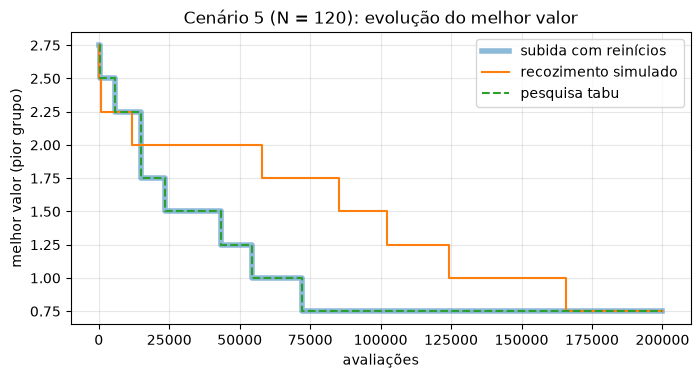

In [28]:
# Executar esta célula

fig, ax = plt.subplots(figsize=(8, 3.8))
estilos = {"subida com reinícios": dict(linewidth=4, alpha=0.5), "recozimento simulado": {},
           "pesquisa tabu": dict(linestyle="--")}
for nome in ALGORITMOS:
    x, y = zip(*historicos[(5, nome, 0)])
    ax.step(x, y, where="post", label=nome, **estilos[nome])
ax.set_xlabel("avaliações")
ax.set_ylabel("melhor valor (pior grupo)")
ax.set_title("Cenário 5 (N = 120): evolução do melhor valor")
ax.legend()
plt.show()

A linha da subida com reinícios (larga) e a da pesquisa tabu (tracejada) coincidem. Não é um erro: partem da mesma solução, usam a mesma vizinhança e o mesmo critério, e enquanto há vizinhos melhores escolhem exatamente os mesmos movimentos. A pesquisa tabu só se distingue **depois** de chegar a um ótimo local: aí a subida recomeça do zero, e a tabu continua a partir do ponto onde está, aceitando pioras. O recozimento desce mais devagar, porque escolhe vizinhos ao acaso em vez do melhor, mas cada passo custa uma só avaliação.

### 10.3 O que a comparação mostra

- No **cenário 3**, os três algoritmos chegam ao mesmo valor em todas as repetições. Isso sugere, sem o provar, que esse valor está perto do ótimo.
- No **cenário 4**, o recozimento e a tabu são consistentes, e a subida com reinícios é a única que varia: numa das repetições fica num valor pior, porque as suas subidas param depressa em ótimos locais.
- No **cenário 5**, com apenas 200 mil avaliações, os três chegam ao mesmo valor. Para os separar seria preciso mais orçamento ou mais repetições (a secção 11 usa o orçamento completo).
- O **tempo de CPU** por avaliação não é igual: o recozimento gera números aleatórios e calcula a energia de todos os grupos em cada passo, por isso gasta mais tempo para o mesmo número de avaliações. Ao comparar por tempo, e não por avaliações, a ordem pode mudar. Por isso o relatório deve indicar **as duas medidas**.
- Com apenas 3 repetições, diferenças pequenas não são conclusivas. Num trabalho a sério, usam-se mais repetições e um teste estatístico.

## 11. Resultados e relatório

### 11.1 Resultados finais

Para os resultados finais usamos o orçamento completo do enunciado (1 milhão de avaliações ou 30 s de CPU) e a combinação que se portou melhor: **pesquisa tabu a partir da solução gulosa**. Nos cenários 1 e 2, comparamos com o ótimo da pesquisa exaustiva.

A função `relatorio` junta toda a informação que o enunciado pede. Valida a solução antes de a apresentar: um relatório com uma solução inválida é pior do que nenhum.

In [29]:
# Executar esta célula

def relatorio(cenario, n, algoritmo, configuracao, estado, info, orcamento):
    assert e_valida(estado.grupos, n), "Solução inválida!"
    print(f"Cenário {cenario} (N = {n})")
    print(f"  Algoritmo: {algoritmo} | configuração: {configuracao}")
    print(f"  Valor (pior grupo): {estado.valor()}")
    print(f"  Avaliações: {orcamento.avaliacoes} | iterações: {info['iterações']} | CPU: {orcamento.cpu():.2f} s")
    for grupo, custo in sorted(zip(estado.grupos, estado.custos), key=lambda gc: sorted(gc[0])):
        print(f"    {sorted(a + 1 for a in grupo)} -> {custo}")


finais = []
for cenario, n in CENARIOS.items():
    A = gerar_incompatibilidades(n).tolist()
    orc = Orcamento(max_avaliacoes=1_000_000, max_cpu=30.0)
    estado, info, _ = pesquisa_tabu(A, divisao_gulosa(A, n), orc, duracao=7)
    referencia = pesquisa_com_poda(A, n)[1] if n <= 12 else "—"
    finais.append({"cenário": cenario, "N": n, "grupos": len(estado.grupos), "valor": estado.valor(),
                   "ótimo conhecido": referencia, "avaliações": orc.avaliacoes,
                   "iterações": info["iterações"], "CPU (s)": round(orc.cpu(), 2)})
    if cenario in (1, 5):
        relatorio(cenario, n, "pesquisa tabu (vizinhança focada, início guloso)",
                  "duração tabu = 7; desempate pela soma dos quadrados", estado, info, orc)
        print()

pd.DataFrame(finais).set_index("cenário")

Cenário 1 (N = 6)
  Algoritmo: pesquisa tabu (vizinhança focada, início guloso) | configuração: duração tabu = 7; desempate pela soma dos quadrados
  Valor (pior grupo): 1.25
  Avaliações: 36 | iterações: 3 | CPU: 0.00 s
    [1, 3, 5] -> 1.25
    [2, 4, 6] -> 1.25



Cenário 5 (N = 120)
  Algoritmo: pesquisa tabu (vizinhança focada, início guloso) | configuração: duração tabu = 7; desempate pela soma dos quadrados
  Valor (pior grupo): 0.5
  Avaliações: 1000000 | iterações: 592 | CPU: 4.37 s
    [1, 59, 67] -> 0.5
    [2, 46, 95] -> 0.25
    [3, 63, 80] -> 0.5
    [4, 61, 119] -> 0.5
    [5, 7, 116] -> 0.5
    [6, 76, 113] -> 0.5
    [8, 10, 28] -> 0.5
    [9, 24, 109] -> 0.5
    [11, 15, 79] -> 0.5
    [12, 73, 111] -> 0.0
    [13, 20, 81] -> 0.25
    [14, 85, 99] -> 0.5
    [16, 30, 82] -> 0.25
    [17, 60, 107] -> 0.25
    [18, 33, 98] -> 0.5
    [19, 54, 78] -> 0.25
    [21, 22, 62] -> 0.25
    [23, 43, 110] -> 0.25
    [25, 74, 106] -> 0.5
    [26, 38, 48] -> 0.0
    [27, 90, 118] -> 0.5
    [29, 101, 105] -> 0.5
    [31, 36, 69] -> 0.5
    [32, 104, 120] -> 0.25
    [34, 44, 77] -> 0.5
    [35, 49, 97] -> 0.5
    [37, 52, 53] -> 0.25
    [39, 65, 117] -> 0.5
    [40, 100, 103] -> 0.5
    [41, 50, 72] -> 0.5
    [42, 51, 94] -> 0.5
    [45, 66

,N,grupos,valor,ótimo conhecido,avaliações,iterações,CPU (s)
cenário,,,,,,,
1,6,2,1.25,1.25,36,3,0.00
2,12,4,1.50,1.5,1000000,27048,2.44
3,24,8,1.00,—,1000000,8234,3.16
4,60,20,0.75,—,1000000,1055,3.66
5,120,40,0.50,—,1000000,592,4.37


Alguns pormenores a notar nos resultados:

- Nos cenários 1 e 2, a pesquisa tabu encontra o ótimo conhecido. No cenário 1 para quase logo: a vizinhança é tão pequena que, ao fim de poucas iterações, todos os movimentos estão na lista tabu.
- Os tempos de CPU dependem do computador; os valores e as avaliações não (com a mesma semente, os resultados são reprodutíveis).
- Partir da solução gulosa ajuda: no cenário 5, a tabu chega a um valor melhor do que na comparação da secção 10, que partia de divisões aleatórias com um orçamento cinco vezes menor.

### 11.2 Como apresentar o trabalho

Um relatório de um problema de otimização deve permitir a outra pessoa **perceber o problema, repetir a experiência e confiar nos números**:

1. **Análise do problema:** a formulação (solução, restrições, função objetivo minimax), o tamanho do espaço de soluções, a classificação (NP-difícil) e as suas consequências práticas.
2. **Algoritmos:** o nome de cada um tal como aparece na bibliografia (subida de colina com reinícios aleatórios, recozimento simulado, pesquisa tabu), a representação da solução, os movimentos e a vizinhança, a função de avaliação (e o desempate ou a energia, se forem diferentes do critério final).
3. **Configuração:** todos os parâmetros (duração tabu, temperaturas, orçamento) e as sementes.
4. **Resultados:** para cada cenário, os grupos, o valor, o número de avaliações, de iterações (ou gerações, num algoritmo genético) e o tempo de CPU, indicando o computador usado.
5. **Discussão:** como se comparam os algoritmos, o que se sabe sobre a qualidade (ótimos conhecidos, consistência entre repetições) e as limitações.

## 12. Experimenta

### Exercício 1 – Minimizar a soma em vez do pior grupo

Na pesquisa tabu, troca a função `objetivo` por uma que minimiza a **soma** dos custos (com o pior grupo como desempate) e executa-a no cenário 3 com 200 mil avaliações. Compara o pior grupo e a soma da solução obtida com os da versão minimax.

Dica: a `pesquisa_tabu` usa a função global `objetivo`, por isso podes guardar a original, redefini-la, correr e repor. Usa `focada=False`, porque a vizinhança focada só faz sentido para o minimax.

In [30]:
# Executar esta célula

# Escreve aqui o código do exercício 1

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
objetivo_minimax = objetivo


def objetivo_soma(custos):
    return (sum(custos), max(custos))


resultados_ex1 = {}
for nome, funcao in (("minimax", objetivo_minimax), ("soma", objetivo_soma)):
    objetivo = funcao
    orc = Orcamento(max_avaliacoes=200_000)
    estado, info, _ = pesquisa_tabu(A24, divisao_gulosa(A24, 24), orc, duracao=7, focada=(nome == "minimax"))
    resultados_ex1[nome] = (estado.valor(), sum(estado.custos))
objetivo = objetivo_minimax  # repor a função original

for nome, (pior, soma) in resultados_ex1.items():
    print(f"Objetivo {nome:8s}: pior grupo {pior} | soma {soma}")
```

A versão «soma» obtém uma soma total mais baixa (6,25 contra 6,5), mas um pior grupo mais alto (1,25 contra 1,0): reparte a incompatibilidade de forma menos justa. É a diferença da secção 2.3, agora com os dados do caso.

</details>

### Exercício 2 – Uma referência mínima: pesquisa aleatória

Qualquer algoritmo deve bater a **pesquisa aleatória**: gerar divisões ao acaso até esgotar o orçamento e guardar a melhor. Implementa-a com o mesmo `Orcamento` e compara-a, no cenário 3 e com 200 mil avaliações, com os resultados da secção 10.

In [31]:
# Executar esta célula

# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def pesquisa_aleatoria(A, n, orcamento, rng):
    melhor, melhor_valor = None, math.inf
    while not orcamento.esgotado():
        divisao = divisao_aleatoria(n, rng)
        orcamento.gastar()
        v = valor_divisao(A, divisao)
        if v < melhor_valor:
            melhor, melhor_valor = divisao, v
    return melhor, melhor_valor


orc = Orcamento(max_avaliacoes=200_000)
_, v = pesquisa_aleatoria(A24, 24, orc, np.random.default_rng(0))
print(f"Pesquisa aleatória, cenário 3: {v} ({orc.cpu():.1f} s)")
print(resumo.loc[3, "melhor"])
```

A pesquisa aleatória fica atrás dos três algoritmos (1,25 contra 1,0) e demora cerca de dez vezes mais, porque cada avaliação calcula a divisão inteira do zero. Num espaço com $10^{15}$ divisões, 200 mil amostras ao acaso quase nunca caem numa das boas.

</details>

### Exercício 3 – Afinar o recozimento

Experimenta o recozimento simulado no cenário 4 com três temperaturas iniciais (0,5; 0,05 e 0,005), mantendo `t_final=0.001`, o mesmo orçamento de 200 mil avaliações e três sementes. Qual funciona melhor, e porquê?

In [32]:
# Executar esta célula

# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for t_inicial in (0.5, 0.05, 0.005):
    valores = []
    for semente in range(3):
        inicial = divisao_aleatoria(60, np.random.default_rng(100 + semente))
        orc = Orcamento(max_avaliacoes=200_000)
        estado, info, _ = recozimento_simulado(A60, inicial, orc, np.random.default_rng(semente),
                                               t_inicial=t_inicial, t_final=0.001)
        valores.append(estado.valor())
    print(f"T inicial = {t_inicial}: {valores}")
```

Com $T_0 = 0{,}005$, o recozimento comporta-se quase como a subida de colina: aceita muito poucas pioras e, em duas das três repetições, fica preso num valor pior. Com 0,5 e 0,05 o resultado é o mesmo. Uma temperatura alta gasta a parte inicial do orçamento a aceitar quase tudo, como uma pesquisa aleatória; aqui sobra orçamento para recuperar, mas com menos avaliações a diferença apareceria. A temperatura certa depende da escala dos $\Delta$: uma regra prática é escolher $T_0$ de modo que, no início, se aceite cerca de metade das pioras.

</details>

## Verifica o que aprendeste

1. Quais são os três elementos da formulação de um problema de otimização? Indica-os para este caso.
2. Porque é que minimizar o pior grupo pode dar uma divisão diferente da que minimiza a soma?
3. Qual é a diferença entre NP-completo e NP-difícil? Porque se diz que este problema é NP-difícil e não NP-completo?
4. Porque se divide por $r_s!$ na contagem das divisões?
5. O que faz a poda na pesquisa exaustiva, e porque continua a garantir o ótimo?
6. Porque é que a avaliação incremental é mais rápida, e como se verifica que está correta?
7. O que é uma planície, e que duas soluções usámos para lidar com ela?
8. Porque é que a vizinhança focada pode ser usada sem perder melhorias do valor?
9. O que é um ótimo local, e que estratégia usa cada um dos três algoritmos para escapar dele?
10. Para que serve o critério de aspiração na pesquisa tabu?
11. Que condições tornam justa uma comparação entre algoritmos, e que medidas de esforço se devem reportar?

<details>
<summary><b>Ver respostas</b></summary>

1. A representação da solução (uma lista de grupos com todos os alunos), as restrições (grupos de 3 a 5, cada aluno uma só vez) e a função objetivo (o pior grupo, a minimizar).
2. A soma pode ser baixa com um grupo muito alto, compensado por grupos muito baixos. O minimax obriga a repartir a incompatibilidade, nem que a soma suba.
3. NP-completo refere-se a problemas de decisão que estão em NP e são tão difíceis como qualquer outro de NP. NP-difícil inclui problemas pelo menos tão difíceis, que não precisam de estar em NP nem de ser de decisão. A versão de otimização («qual é a melhor divisão?») não é um problema de decisão, por isso é NP-difícil; a versão de decisão («existe uma divisão com valor ≤ v?») é NP-completa.
4. Porque grupos do mesmo tamanho trocados entre si dão a mesma divisão, e a fórmula com $N!$ contá-las-ia como diferentes.
5. Abandona um ramo assim que um grupo já construído tem custo igual ou superior ao melhor valor conhecido. Como o valor é o pior grupo, nenhuma divisão desse ramo poderia ser melhor, por isso não se perde o ótimo.
6. Porque um movimento só altera dois grupos e, nesses, apenas os pares que envolvem os alunos que se mexeram. Verifica-se comparando, ao longo de muitos movimentos aleatórios, os custos incrementais com um cálculo do zero.
7. Uma região em que muitos vizinhos têm o mesmo valor, o que tira a direção à pesquisa. Usámos um desempate pela soma dos quadrados (subida e tabu) e uma energia «máximo suave» (recozimento).
8. Porque o valor é o pior grupo: um movimento que não mexe em nenhum grupo com o custo máximo não o pode baixar.
9. Uma solução sem vizinhos melhores, que pode não ser a melhor de todas. A subida recomeça de outro ponto (reinícios); o recozimento aceita pioras com uma probabilidade que diminui com a temperatura; a tabu aceita o melhor vizinho mesmo que seja pior e proíbe voltar atrás durante algumas iterações.
10. Permite um movimento tabu quando ele leva a uma solução melhor do que a melhor encontrada. A lista tabu existe para evitar ciclos, e uma solução nova recorde não pode ser um ciclo.
11. O mesmo orçamento, a mesma solução inicial, os mesmos dados e várias repetições com sementes diferentes. Devem reportar-se as avaliações, as iterações (ou gerações) e o tempo de CPU, com o computador usado.

</details>

## Leitura recomendada

- Russell, S. e Norvig, P. (2021). *[Artificial Intelligence: A Modern Approach](https://aima.cs.berkeley.edu/)* (4.ª ed.). Hoboken: Pearson. Capítulo 4 (pesquisa local: subida de colina, recozimento simulado, algoritmos genéticos).
- Michalewicz, Z. e Fogel, D. B. (2004). *How to Solve It: Modern Heuristics* (2.ª ed.). Berlim: Springer. Formulação de problemas, pesquisa local, recozimento simulado e pesquisa tabu, com muitos exemplos.
- Glover, F. e Laguna, M. (1997). *Tabu Search*. Boston: Kluwer Academic Publishers. A referência sobre pesquisa tabu, do seu criador.
- Kirkpatrick, S., Gelatt, C. D. e Vecchi, M. P. (1983). [Optimization by simulated annealing](https://doi.org/10.1126/science.220.4598.671). *Science*, 220(4598), 671–680. O artigo que introduziu o recozimento simulado.
- Garey, M. R. e Johnson, D. S. (1979). *Computers and Intractability: A Guide to the Theory of NP-Completeness*. Nova Iorque: W. H. Freeman. A referência sobre NP-completude; inclui o problema da partição em triângulos.
- **Módulos relacionados:** capítulos 18 (recursão) e 25 (geradores), usados na pesquisa exaustiva; N3_04 (descida do gradiente), a versão contínua da mesma ideia de «melhorar passo a passo».